<a href="https://colab.research.google.com/github/MrVilli/hola/blob/main/ensayoSolemne1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración estética para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True})

# Carga de datos
archivo = "BaseDatos_Energia_FMSP316.xlsx"
df = pd.read_excel(archivo, sheet_name="Datos")
print(df.head())

# Pregunta 2.1
media_cee = df["CEE_kWh_ton"].mean()
mediana_cee = df["CEE_kWh_ton"].median()
print(f"Media CEE global: {media_cee:.2f} kWh/ton")
print(f"Mediana CEE global: {mediana_cee:.2f} kWh/ton")

# Pregunta 2.2
moda_paradas = df["Paradas_No_Programadas"].mode()[0]
moda_eficiencia = df["Categoría_Eficiencia"].mode()[0]
print(f"Moda Paradas No Programadas: {moda_paradas}")
print(f"Moda Categoría Eficiencia: {moda_eficiencia}")

   ID_Registro         Planta   Turno   Tipo_Equipo_Principal  \
0         2001  Planta Centro  Mañana            Sistema HVAC   
1         2002   Planta Norte   Noche  Iluminación industrial   
2         2003  Planta Centro  Mañana            Sistema HVAC   
3         2004  Planta Centro   Tarde     Compresores de aire   
4         2005  Planta Centro   Noche     Hornos industriales   

  Mantenimiento_Al_Día  CEE_kWh_ton  Factor_Potencia  Paradas_No_Programadas  \
0                   No       86.648            0.944                       0   
1                   Sí       80.395            0.956                       2   
2                   Sí       76.297            0.953                       0   
3                   No       84.847            0.952                       0   
4                   Sí       83.829            0.956                       0   

   Potencia_Nominal_kW  Horas_Operación_día Categoría_Eficiencia  \
0                 32.0                 16.5                 

In [5]:
# Pregunta 2.1
media_cee = df["CEE_kWh_ton"].mean()
mediana_cee = df["CEE_kWh_ton"].median()
print(f"Media CEE global: {media_cee:.2f} kWh/ton")
print(f"Mediana CEE global: {mediana_cee:.2f} kWh/ton")

# Pregunta 2.2
moda_paradas = df["Paradas_No_Programadas"].mode()[0]
moda_eficiencia = df["Categoría_Eficiencia"].mode()[0]
print(f"Moda Paradas No Programadas: {moda_paradas}")
print(f"Moda Categoría Eficiencia: {moda_eficiencia}")

Media CEE global: 84.18 kWh/ton
Mediana CEE global: 83.47 kWh/ton
Moda Paradas No Programadas: 0
Moda Categoría Eficiencia: B


In [6]:
# Pregunta 3.1: Cálculo por planta
res = []
for p, g in df.groupby("Planta"):
    cee = g["CEE_kWh_ton"]
    res.append(
        {
            "Planta": p,
            "Rango": cee.max() - cee.min(),
            "Varianza": cee.var(ddof=1),
            "Desv.Est": cee.std(ddof=1),
            "CV (%)": (cee.std(ddof=1) / cee.mean()) * 100,
        }
    )
print(pd.DataFrame(res).to_string(index=False))

       Planta  Rango  Varianza  Desv.Est   CV (%)
Planta Centro 34.400 16.857645  4.105806 4.942681
 Planta Norte 22.921 12.814184  3.579690 4.351157
   Planta Sur 44.409 67.976871  8.244809 9.456304


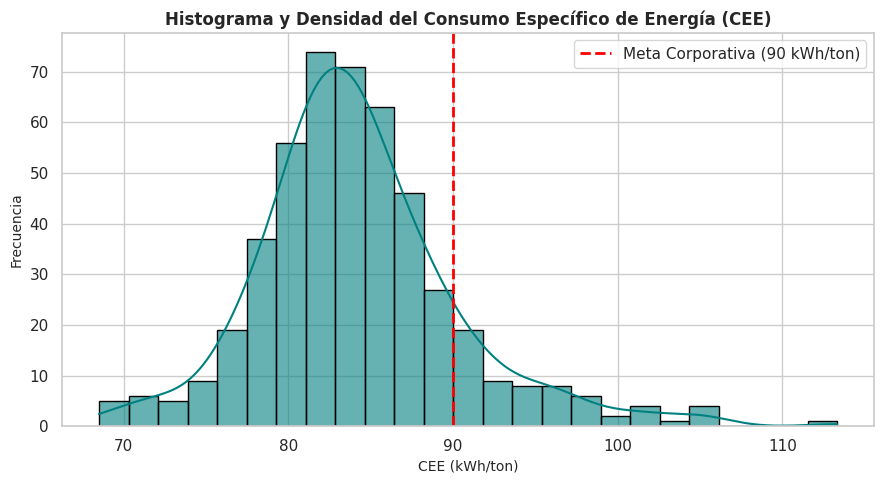

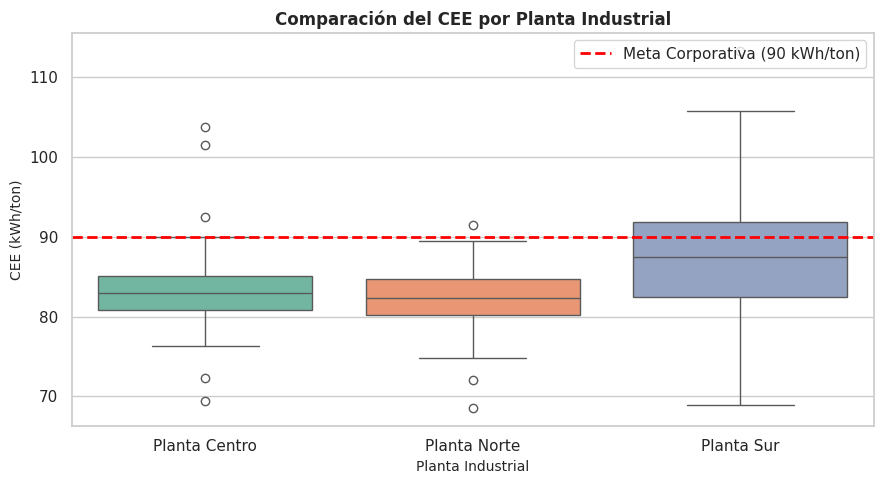

In [7]:
# Pregunta 5.1: Histograma global
plt.figure(figsize=(9, 5))
sns.histplot(
    df["CEE_kWh_ton"],
    bins=25,
    kde=True,
    color="teal",
    edgecolor="black",
    alpha=0.6,
)
plt.axvline(
    90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Meta Corporativa (90 kWh/ton)",
)
plt.title(
    "Histograma y Densidad del Consumo Específico de Energía (CEE)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("CEE (kWh/ton)", fontsize=10)
plt.ylabel("Frecuencia", fontsize=10)
plt.legend()
plt.show()

# Pregunta 5.2: Boxplot comparativo
plt.figure(figsize=(9, 5))
sns.boxplot(
    x="Planta",
    y="CEE_kWh_ton",
    data=df,
    palette="Set2",
    hue="Planta",
    legend=False,
)
plt.axhline(
    90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Meta Corporativa (90 kWh/ton)",
)
plt.title(
    "Comparación del CEE por Planta Industrial",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Planta Industrial", fontsize=10)
plt.ylabel("CEE (kWh/ton)", fontsize=10)
plt.legend(loc="upper right")
plt.show()